# Analisis Pengangguran di India dengan Python
**CodeAlpha Data Science Internship — Task 2: Unemployment Analysis with Python**

Tujuan project:
1. Membersihkan (*cleaning*) dan mengeksplorasi data tingkat pengangguran India.
2. Memvisualisasikan tren pengangguran.
3. Menganalisis dampak **Covid-19** terhadap tingkat pengangguran.
4. Mencari pola / tren musiman.
5. Merumuskan insight untuk kebijakan ekonomi & sosial.

**Dataset:** `Unemployment_in_India.csv` (data bulanan Mei 2019 – Juni 2020, per negara bagian, area Rural/Urban).

## Langkah 1 — Import Library
Kita memerlukan `pandas` & `numpy` untuk mengolah data, `matplotlib` & `seaborn` untuk visualisasi, dan `scipy` untuk uji statistik sederhana.

In [23]:
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install scipy

In [24]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 100

## Langkah 2 — Memuat Dataset
Membaca file CSV ke dalam `DataFrame`. Ubah `FILE_PATH` sesuai lokasi file di komputer Anda.

In [25]:
df_raw = pd.read_csv("Unemployment in India.csv")
df_raw.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## Langkah 3 — Inspeksi Awal Data
Sebelum membersihkan, kita perlu tahu: ukuran data, tipe kolom, nilai kosong, dan duplikat.
Pada tahap ini biasanya ditemukan masalah seperti **nama kolom yang memiliki spasi di depan** dan **baris kosong**.

In [26]:
print("Ukuran data (baris, kolom):", df_raw.shape)
print("\nNama kolom (perhatikan spasi di awal):")
print(list(df_raw.columns))
print("\nInfo data:")
df_raw.info()

Ukuran data (baris, kolom): (768, 7)

Nama kolom (perhatikan spasi di awal):
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Info data:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory 

In [27]:
print("Jumlah nilai kosong per kolom:")
print(df_raw.isnull().sum())
print("\nJumlah baris duplikat (termasuk baris kosong):", df_raw.duplicated().sum())

Jumlah nilai kosong per kolom:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Jumlah baris duplikat (termasuk baris kosong): 27


## Langkah 4 — Data Cleaning
Yang dilakukan:
1. Menghapus spasi di nama kolom & mempersingkat namanya.
2. Menghapus baris yang seluruhnya kosong (28 baris kosong di akhir file).
3. Menghapus spasi pada nilai teks (mis. `' 31-05-2019'`).
4. Mengubah kolom tanggal menjadi tipe `datetime`.
5. Menambah kolom turunan: `Month`, `Month_Name`, dan **`Period`** (Pre-Covid / Lockdown / Pemulihan).

**Penentuan periode Covid-19** (lockdown nasional India dimulai 25 Maret 2020):
- **Pre-Covid**: Mei 2019 – Maret 2020
- **Lockdown**: April 2020 – Mei 2020 (lockdown paling ketat)
- **Pemulihan (Unlock)**: Juni 2020

In [28]:
df = df_raw.copy()

# 1. rapikan nama kolom
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
})

# 2. hapus baris kosong total
df = df.dropna(how="all").reset_index(drop=True)

# 3. rapikan nilai teks
for col in ["Region", "Frequency", "Area", "Date"]:
    df[col] = df[col].astype(str).str.strip()

# 4. ubah ke datetime
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

# 5. kolom turunan
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")

def tentukan_periode(d):
    if d < pd.Timestamp("2020-04-01"):
        return "Pre-Covid"
    elif d <= pd.Timestamp("2020-05-31"):
        return "Lockdown"
    return "Pemulihan"

df["Period"] = df["Date"].apply(tentukan_periode)
df["Period"] = pd.Categorical(df["Period"], ["Pre-Covid", "Lockdown", "Pemulihan"], ordered=True)

print("Ukuran data setelah cleaning:", df.shape)
print("Nilai kosong tersisa:", df.isnull().sum().sum())
print("Duplikat tersisa:", df.duplicated().sum())
df.head()

Ukuran data setelah cleaning: (740, 10)
Nilai kosong tersisa: 0
Duplikat tersisa: 0


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area,Month,Month_Name,Period
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,5,May,Pre-Covid
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural,6,Jun,Pre-Covid
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,7,Jul,Pre-Covid
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,8,Aug,Pre-Covid
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,9,Sep,Pre-Covid


## Langkah 5 — Eksplorasi Data (EDA)
### 5.1 Ringkasan struktur dan statistik deskriptif

In [29]:
print("Rentang waktu :", df["Date"].min().date(), "s/d", df["Date"].max().date())
print("Jumlah region :", df["Region"].nunique())
print("Frekuensi     :", df["Frequency"].unique())
print("Area          :", df["Area"].unique())
print()
df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].describe().round(2)

Rentang waktu : 2019-05-31 s/d 2020-06-30
Jumlah region : 28
Frekuensi     : <ArrowStringArray>
['Monthly']
Length: 1, dtype: str
Area          : <ArrowStringArray>
['Rural', 'Urban']
Length: 2, dtype: str



,Unemployment_Rate,Employed,Labour_Participation_Rate
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


### 5.2 Distribusi tingkat pengangguran
Histogram menunjukkan sebaran nilai, boxplot membandingkan **Rural vs Urban**. Perhatikan adanya *outlier* di sisi kanan (nilai sangat tinggi) — itu bukan error, melainkan dampak lockdown di bulan April–Mei 2020.

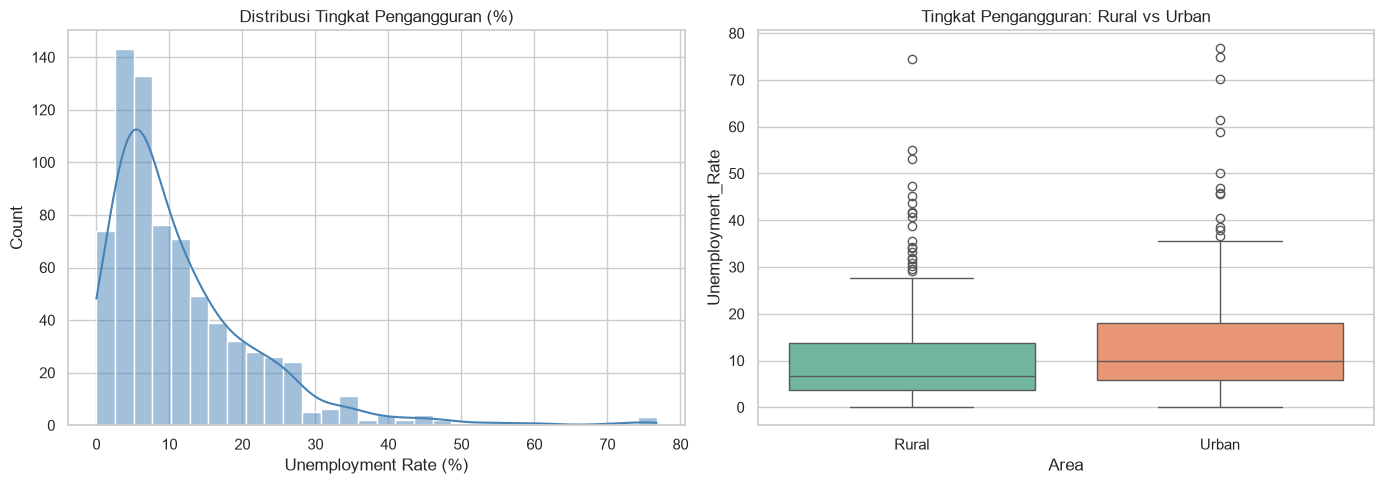

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Unemployment_Rate"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribusi Tingkat Pengangguran (%)")
ax[0].set_xlabel("Unemployment Rate (%)")

sns.boxplot(data=df, x="Area", y="Unemployment_Rate", ax=ax[1], palette="Set2")
ax[1].set_title("Tingkat Pengangguran: Rural vs Urban")

plt.tight_layout()
plt.show()

### 5.3 Tren pengangguran bulanan (rata-rata seluruh negara bagian)
Garis merah putus-putus menandai awal lockdown nasional (25 Maret 2020).

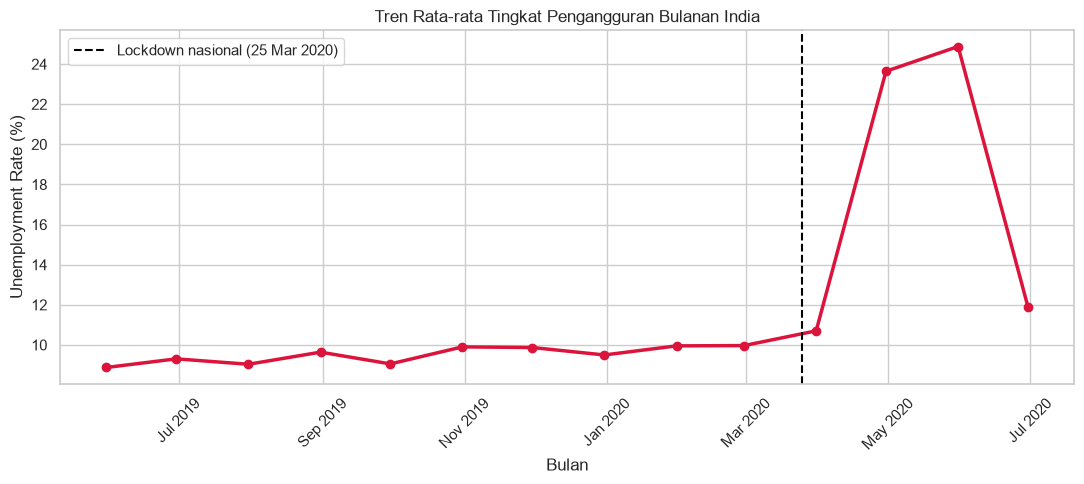

,Rata-rata Unemployment Rate (%)
Date,
2019-05-31,8.87
2019-06-30,9.30
2019-07-31,9.03
2019-08-31,9.64
2019-09-30,9.05
2019-10-31,9.90
2019-11-30,9.87
2019-12-31,9.50
2020-01-31,9.95


In [31]:
monthly = df.groupby("Date")["Unemployment_Rate"].mean()

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, marker="o", linewidth=2.5, color="crimson")
ax.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", label="Lockdown nasional (25 Mar 2020)")
ax.set_title("Tren Rata-rata Tingkat Pengangguran Bulanan India")
ax.set_xlabel("Bulan"); ax.set_ylabel("Unemployment Rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

monthly.round(2).to_frame("Rata-rata Unemployment Rate (%)")

### 5.4 Tren Rural vs Urban
Membandingkan apakah dampak Covid-19 berbeda antara wilayah pedesaan dan perkotaan.

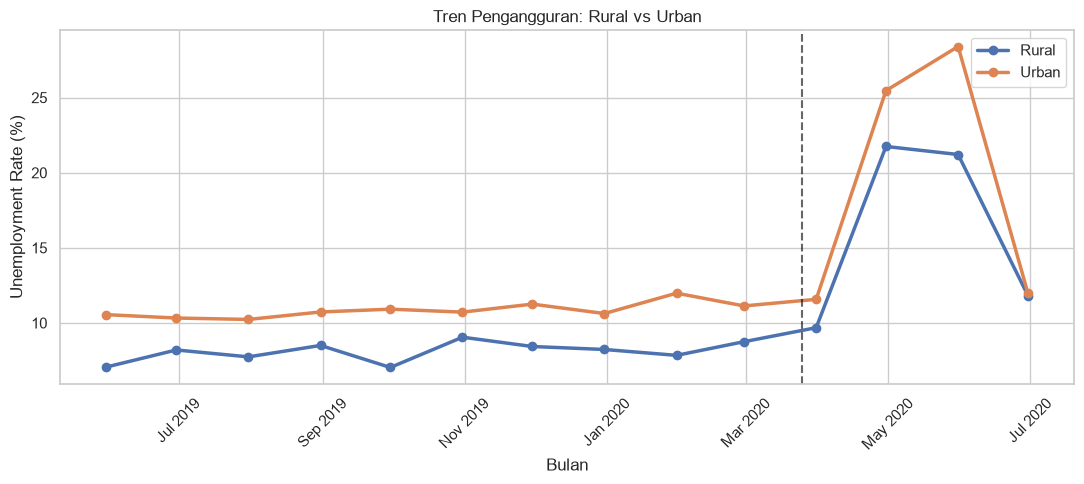

Area,Rural,Urban
Date,,
2019-05-31,7.07,10.55
2019-06-30,8.20,10.33
2019-07-31,7.74,10.23
2019-08-31,8.50,10.73
2019-09-30,7.04,10.92
2019-10-31,9.05,10.72
2019-11-30,8.43,11.25
2019-12-31,8.23,10.63
2020-01-31,7.84,11.98


In [32]:
area_trend = df.pivot_table(index="Date", columns="Area", values="Unemployment_Rate", aggfunc="mean")

fig, ax = plt.subplots()
for area in area_trend.columns:
    ax.plot(area_trend.index, area_trend[area], marker="o", linewidth=2.5, label=area)
ax.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", alpha=0.6)
ax.set_title("Tren Pengangguran: Rural vs Urban")
ax.set_xlabel("Bulan"); ax.set_ylabel("Unemployment Rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

area_trend.round(2)

### 5.5 Tren jumlah orang bekerja & tingkat partisipasi tenaga kerja
Pengangguran hanya satu sisi cerita. Kita juga perlu melihat **berapa orang yang masih bekerja** dan **seberapa banyak orang yang aktif di pasar kerja**.

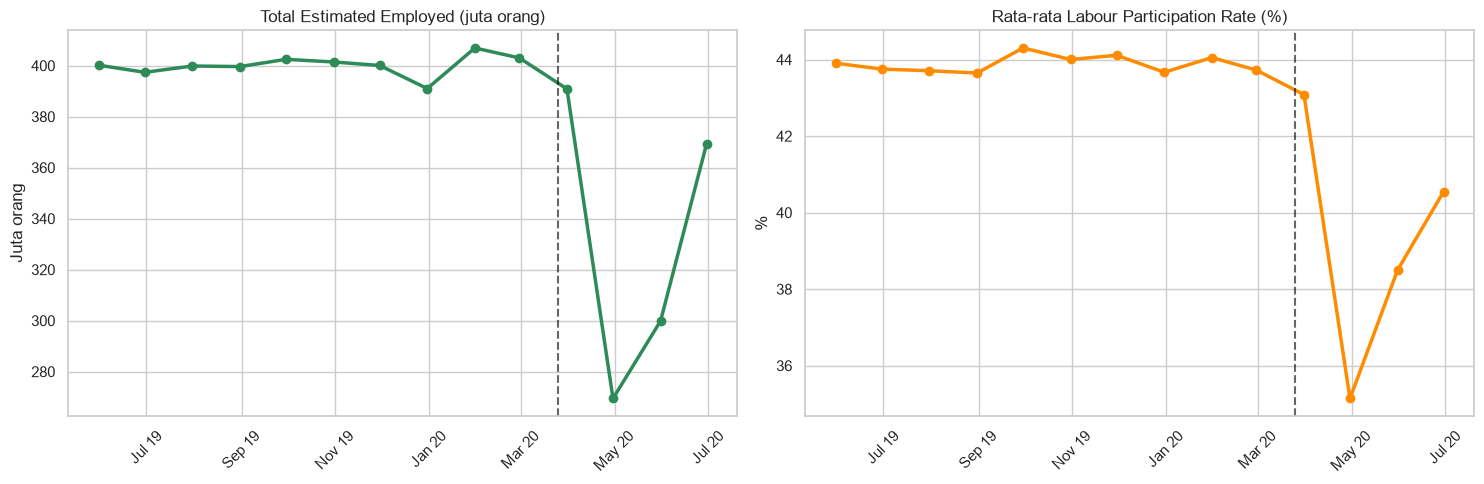

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

emp = df.groupby("Date")["Employed"].sum() / 1e6   # dalam juta orang
ax[0].plot(emp.index, emp.values, marker="o", color="seagreen", linewidth=2.5)
ax[0].set_title("Total Estimated Employed (juta orang)")
ax[0].set_ylabel("Juta orang")

lpr = df.groupby("Date")["Labour_Participation_Rate"].mean()
ax[1].plot(lpr.index, lpr.values, marker="o", color="darkorange", linewidth=2.5)
ax[1].set_title("Rata-rata Labour Participation Rate (%)")
ax[1].set_ylabel("%")

for a in ax:
    a.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", alpha=0.6)
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    a.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Langkah 6 — Analisis Dampak Covid-19
### 6.1 Perbandingan rata-rata antar periode

In [34]:
period_summary = df.groupby("Period", observed=True).agg(
    Rata2_Unemployment=("Unemployment_Rate", "mean"),
    Median_Unemployment=("Unemployment_Rate", "median"),
    Maks_Unemployment=("Unemployment_Rate", "max"),
    Rata2_LPR=("Labour_Participation_Rate", "mean"),
).round(2)
period_summary

,Rata2_Unemployment,Median_Unemployment,Maks_Unemployment,Rata2_LPR
Period,,,,
Pre-Covid,9.61,7.22,34.69,43.82
Lockdown,24.26,19.96,76.74,36.82
Pemulihan,11.90,10.34,35.57,40.55


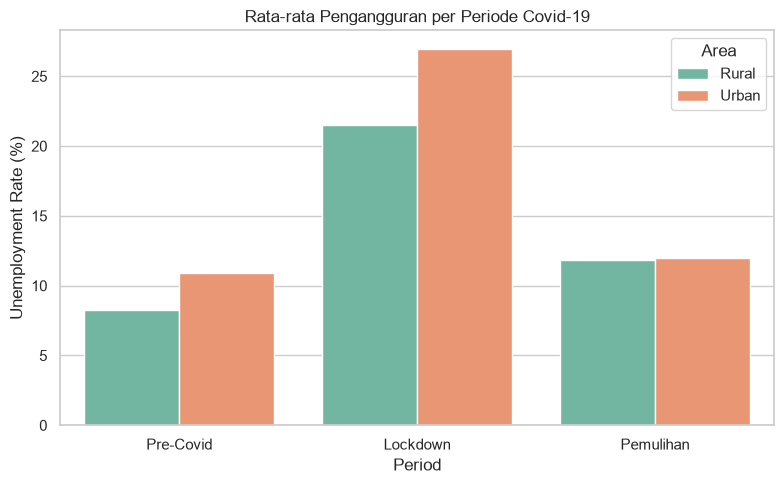

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x="Period", y="Unemployment_Rate", hue="Area", errorbar=None, ax=ax, palette="Set2")
ax.set_title("Rata-rata Pengangguran per Periode Covid-19")
ax.set_ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### 6.2 Uji statistik: apakah kenaikan benar-benar signifikan?
Kita membandingkan pengangguran **Pre-Covid** vs **Lockdown** dengan uji **Mann-Whitney U** (tidak mengasumsikan distribusi normal, cocok karena data sangat *skewed*).
- H0: tidak ada perbedaan tingkat pengangguran antara Pre-Covid dan Lockdown.
- H1: tingkat pengangguran saat Lockdown lebih tinggi.

In [36]:
pre = df.loc[df["Period"] == "Pre-Covid", "Unemployment_Rate"]
lock = df.loc[df["Period"] == "Lockdown", "Unemployment_Rate"]

u_stat, p_val = stats.mannwhitneyu(lock, pre, alternative="greater")
print(f"Rata-rata Pre-Covid : {pre.mean():.2f}%")
print(f"Rata-rata Lockdown  : {lock.mean():.2f}%")
print(f"Kenaikan            : {lock.mean() - pre.mean():.2f} poin persentase ({lock.mean()/pre.mean():.1f}x lipat)")
print(f"Mann-Whitney U = {u_stat:.1f}, p-value = {p_val:.2e}")
print("Kesimpulan:", "SIGNIFIKAN (tolak H0)" if p_val < 0.05 else "Tidak signifikan")

Rata-rata Pre-Covid : 9.61%
Rata-rata Lockdown  : 24.26%
Kenaikan            : 14.64 poin persentase (2.5x lipat)
Mann-Whitney U = 47363.0, p-value = 4.41e-21
Kesimpulan: SIGNIFIKAN (tolak H0)


### 6.3 Negara bagian paling terdampak
Dampak dihitung sebagai selisih antara **rata-rata pengangguran saat Lockdown** dan **rata-rata Pre-Covid** pada tiap negara bagian.

10 negara bagian dengan kenaikan terbesar:


Period,Pre-Covid,Lockdown,Pemulihan,Kenaikan
Region,,,,
Puducherry,1.58,75.42,4.55,73.84
Jharkhand,13.95,57.12,20.45,43.16
Tamil Nadu,3.16,40.85,13.50,37.69
Bihar,13.99,47.25,16.47,33.26
Karnataka,3.27,24.47,8.52,21.20
Madhya Pradesh,4.58,21.85,9.59,17.27
Haryana,23.17,40.30,32.49,17.12
Andhra Pradesh,5.21,21.99,3.36,16.78
Telangana,4.77,21.40,13.11,16.63


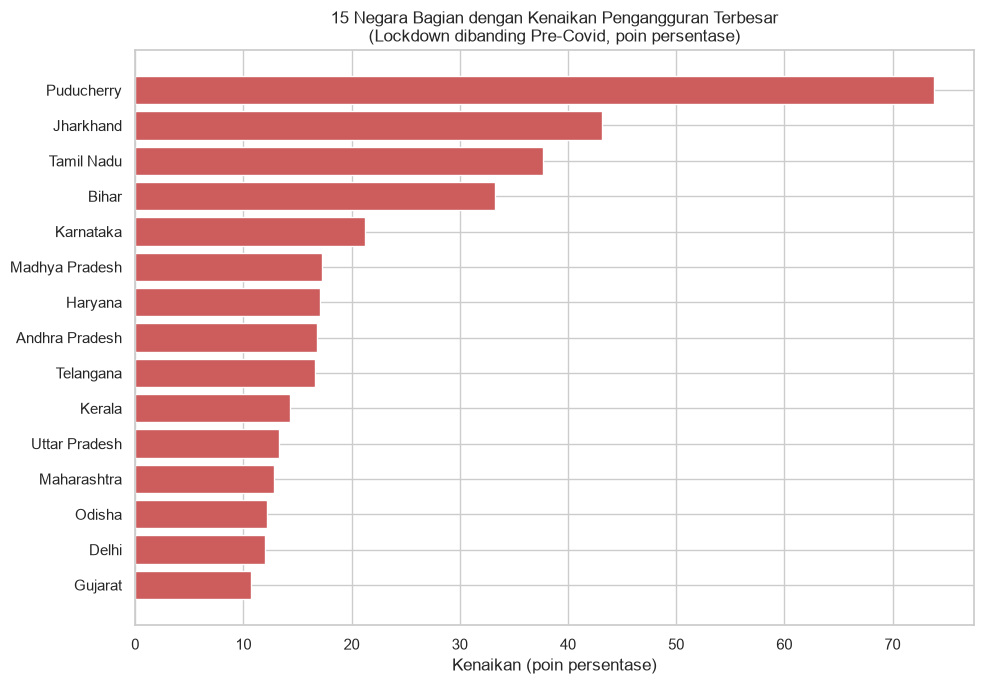

In [37]:
state_period = df.pivot_table(index="Region", columns="Period", values="Unemployment_Rate",
                              aggfunc="mean", observed=True)
state_period["Kenaikan"] = state_period["Lockdown"] - state_period["Pre-Covid"]
impact = state_period.sort_values("Kenaikan", ascending=False).round(2)

print("10 negara bagian dengan kenaikan terbesar:")
display(impact.head(10))

fig, ax = plt.subplots(figsize=(10, 7))
top = impact.head(15).iloc[::-1]
ax.barh(top.index, top["Kenaikan"], color="indianred")
ax.set_title("15 Negara Bagian dengan Kenaikan Pengangguran Terbesar\n(Lockdown dibanding Pre-Covid, poin persentase)")
ax.set_xlabel("Kenaikan (poin persentase)")
plt.tight_layout()
plt.show()

### 6.4 Heatmap pengangguran per negara bagian per bulan
Warna yang lebih gelap = pengangguran lebih tinggi. Terlihat jelas "lonjakan" pada kolom April–Mei 2020.

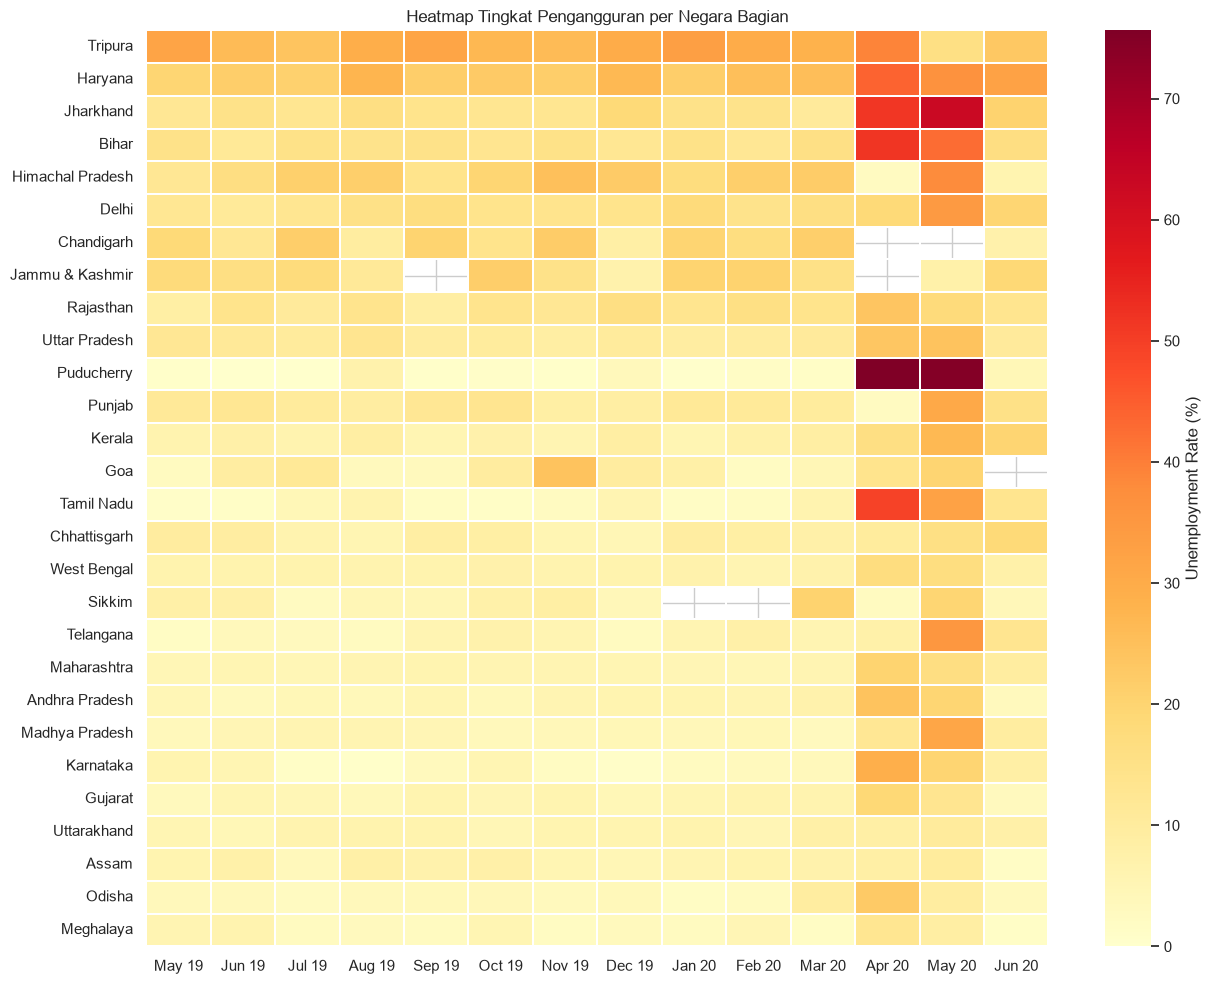

In [38]:
heat = df.pivot_table(index="Region", columns="Date", values="Unemployment_Rate", aggfunc="mean")
heat.columns = [c.strftime("%b %y") for c in heat.columns]
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(13, 10))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.3, cbar_kws={"label": "Unemployment Rate (%)"})
plt.title("Heatmap Tingkat Pengangguran per Negara Bagian")
plt.xlabel(""); plt.ylabel("")
plt.tight_layout()
plt.show()

## Langkah 7 — Pola & Tren Musiman
Karena data hanya mencakup **14 bulan** (Mei 2019 – Juni 2020), kita tidak bisa mengukur musiman secara statistik penuh (butuh minimal 2–3 tahun).
Agar tidak bias oleh Covid-19, analisis musiman hanya memakai periode **Pre-Covid** (Mei 2019 – Maret 2020).

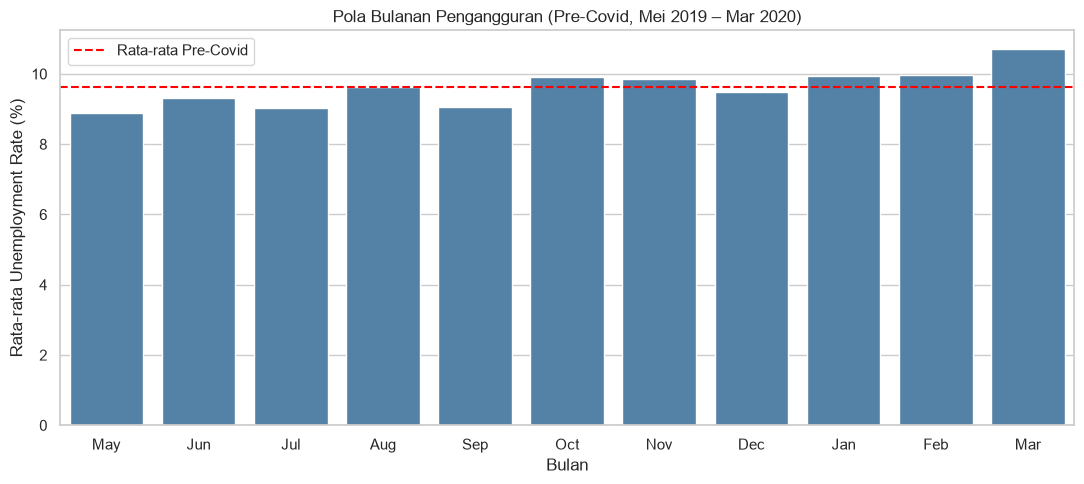

,Month_Name,Unemployment_Rate
0,May,8.87
1,Jun,9.30
2,Jul,9.03
3,Aug,9.64
4,Sep,9.05
5,Oct,9.90
6,Nov,9.87
7,Dec,9.50
8,Jan,9.95
9,Feb,9.96


In [39]:
pre_covid = df[df["Period"] == "Pre-Covid"]
season = pre_covid.groupby("Month_Name")["Unemployment_Rate"].mean().reset_index()

# urutkan sesuai kalender data (Mei 2019 -> Mar 2020)
urutan = ["May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]
season["Month_Name"] = pd.Categorical(season["Month_Name"], urutan, ordered=True)
season = season.sort_values("Month_Name")

fig, ax = plt.subplots()
sns.barplot(data=season, x="Month_Name", y="Unemployment_Rate", color="steelblue", ax=ax)
ax.axhline(pre_covid["Unemployment_Rate"].mean(), color="red", linestyle="--", label="Rata-rata Pre-Covid")
ax.set_title("Pola Bulanan Pengangguran (Pre-Covid, Mei 2019 – Mar 2020)")
ax.set_xlabel("Bulan"); ax.set_ylabel("Rata-rata Unemployment Rate (%)")
ax.legend()
plt.tight_layout()
plt.show()

season[["Month_Name", "Unemployment_Rate"]].round(2).reset_index(drop=True)

### Korelasi antar variabel

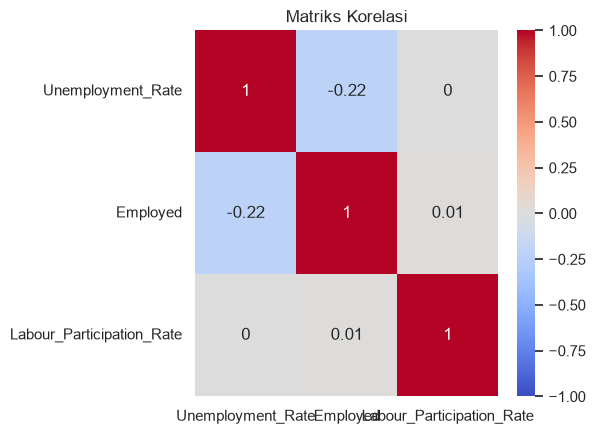

In [40]:
corr = df[["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]].corr().round(2)
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Matriks Korelasi")
plt.tight_layout()
plt.show()

## Langkah 8 — Rata-rata Pengangguran per Negara Bagian (Pre-Covid vs Lockdown)
Melihat negara bagian dengan **pengangguran struktural** tinggi (sudah tinggi sebelum Covid) dan yang **terdampak lonjakan** saat lockdown.

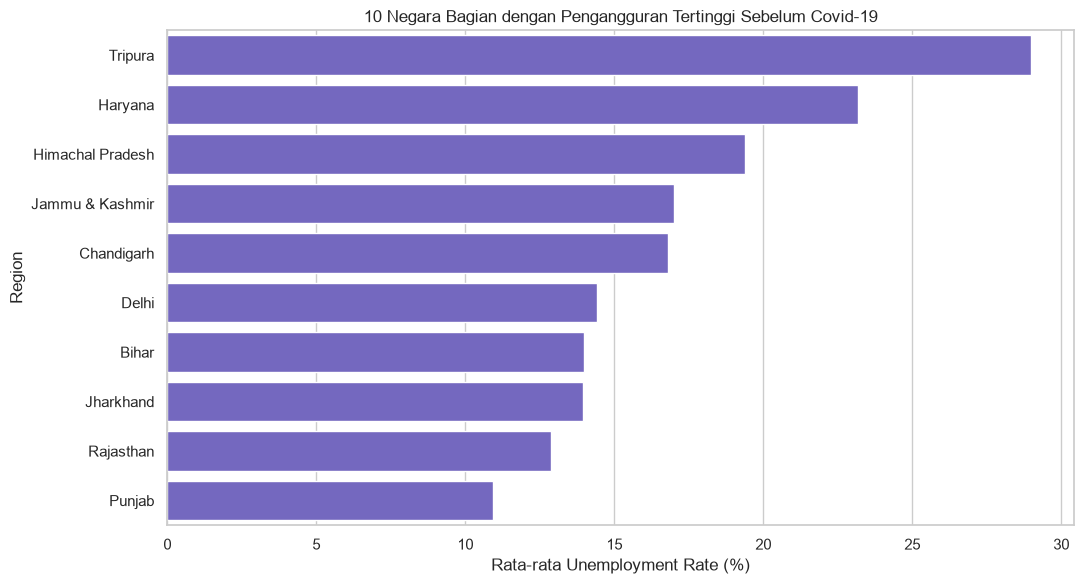

In [41]:
pre_state = (df[df["Period"] == "Pre-Covid"].groupby("Region")["Unemployment_Rate"]
             .mean().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=pre_state.head(10).values, y=pre_state.head(10).index, color="slateblue", ax=ax)
ax.set_title("10 Negara Bagian dengan Pengangguran Tertinggi Sebelum Covid-19")
ax.set_xlabel("Rata-rata Unemployment Rate (%)")
plt.tight_layout()
plt.show()

## Langkah 9 — Menghitung Angka Kunci untuk Kesimpulan
Cell ini menghimpun semua angka penting agar kesimpulan di bawah berbasis data, bukan asumsi.

In [42]:
m = df.groupby("Date")["Unemployment_Rate"].mean()
peak_date = m.idxmax()
pre_avg = df.loc[df["Period"] == "Pre-Covid", "Unemployment_Rate"].mean()

rural_urban = df.pivot_table(index="Period", columns="Area", values="Unemployment_Rate",
                             aggfunc="mean", observed=True).round(2)

emp = df.groupby("Date")["Employed"].sum()
emp_drop = (emp.loc["2020-04-30"] / emp.loc["2020-03-31"] - 1) * 100

print(f"Rata-rata pengangguran Pre-Covid       : {pre_avg:.2f}%")
print(f"Puncak (rata-rata nasional)            : {m.max():.2f}% pada {peak_date.strftime('%B %Y')}")
print(f"Pengangguran Juni 2020 (pemulihan)     : {m.loc['2020-06-30']:.2f}%")
print(f"Perubahan total orang bekerja Mar→Apr  : {emp_drop:.1f}%")
print(f"Negara bagian dengan kenaikan terbesar : {impact.index[0]} (+{impact['Kenaikan'].iloc[0]:.1f} poin)")
print()
print("Rata-rata pengangguran Rural vs Urban per periode:")
display(rural_urban)

Rata-rata pengangguran Pre-Covid       : 9.61%
Puncak (rata-rata nasional)            : 24.88% pada May 2020
Pengangguran Juni 2020 (pemulihan)     : 11.90%
Perubahan total orang bekerja Mar→Apr  : -31.1%
Negara bagian dengan kenaikan terbesar : Puducherry (+73.8 poin)

Rata-rata pengangguran Rural vs Urban per periode:


Area,Rural,Urban
Period,,
Pre-Covid,8.23,10.91
Lockdown,21.48,26.93
Pemulihan,11.83,11.98


## Langkah 10 — Kesimpulan dan Rekomendasi
Lihat bagian **Kesimpulan Akhir** di bawah (diisi berdasarkan output cell-cell di atas).

# 🏁 Kesimpulan Akhir

## Temuan Utama (berdasarkan output di atas)

| Aspek | Temuan |
|---|---|
| Kondisi **Pre-Covid** (Mei 2019 – Mar 2020) | Rata-rata pengangguran relatif stabil di kisaran **±9–10%** (rata-rata 9,61%) |
| Dampak **Lockdown** (Apr – Mei 2020) | Melonjak ke **24,26%** (naik **±14,6 poin persentase, ±2,5×**). Puncak rata-rata bulanan **24,88% pada Mei 2020** |
| Signifikansi statistik | Uji Mann-Whitney: **p ≈ 4,4×10⁻²¹** → kenaikan sangat signifikan |
| **Pemulihan** (Juni 2020) | Turun tajam ke **11,90%**, tetapi masih **di atas** level Pre-Covid |
| Rural vs Urban | Urban lebih terpukul: **26,9%** vs Rural **21,5%** saat lockdown. Pada Juni 2020 keduanya hampir sama (±11,9%) |
| Orang bekerja | Total estimasi orang bekerja turun dari ±391 juta (Mar) ke ±269 juta (Apr), **sekitar −31%** (catatan: jumlah wilayah yang tercatat berbeda antar bulan) |
| Partisipasi tenaga kerja | Turun dari ±43–44% menjadi ±35% (Apr 2020), lalu pulih ke ±40,6% (Jun 2020) |
| Negara bagian paling terdampak | **Puducherry** (+73,8 poin), **Jharkhand** (+43,2), **Tamil Nadu** (+37,7), **Bihar** (+33,3), **Karnataka** (+21,2) |
| Pengangguran tinggi sebelum Covid | **Tripura** (±29%), **Haryana** (±23%), **Himachal Pradesh** (±19%) → indikasi masalah **struktural** |
| Pemulihan belum merata | Pada Juni 2020, **18 dari 26** negara bagian (yang datanya lengkap) masih di atas level Pre-Covid; contoh: **Kerala, Chhattisgarh, Tamil Nadu, Haryana** |

## Pola dan Tren Musiman
- Sebelum Covid-19, pengangguran cenderung **naik perlahan** dari ±8,9% (Mei 2019) ke ±10,7% (Mar 2020), tanpa lonjakan musiman yang tajam.
- **Lonjakan April–Mei 2020 bukan pola musiman**, melainkan **guncangan eksternal** (lockdown Covid-19).
- ⚠️ **Keterbatasan:** data hanya 14 bulan sehingga **musiman sejati tidak dapat dibuktikan** secara statistik. Dibutuhkan data minimal 2–3 tahun.

## Rekomendasi Kebijakan
1. **Jaring pengaman sosial cepat tanggap** (bantuan tunai, tunjangan pengangguran sementara) untuk pekerja informal, karena dampak terbesar terjadi hanya dalam hitungan minggu.
2. **Perhatian khusus wilayah urban** (pekerja migran, buruh harian, sektor jasa) yang terpukul paling keras saat pembatasan mobilitas.
3. **Dukungan yang ditargetkan per wilayah**: prioritas ke negara bagian dengan lonjakan terbesar (Puducherry, Jharkhand, Tamil Nadu, Bihar) dan yang pemulihannya lambat (Kerala, Chhattisgarh, Haryana).
4. **Atasi pengangguran struktural** di wilayah yang sudah tinggi sebelum pandemi (Tripura, Haryana, Himachal Pradesh) lewat pelatihan keterampilan dan pembukaan lapangan kerja.
5. **Perkuat program padat karya pedesaan dan UMKM** sebagai penyangga ekonomi saat krisis, serta dorong digitalisasi/kerja jarak jauh agar lebih tahan guncangan.
6. **Bangun sistem pemantauan pasar kerja berkala** (data bulanan/real-time) agar kebijakan bisa responsif.

## Keterbatasan Analisis
- Rata-rata dihitung dari rata-rata sederhana antar negara bagian/area (**tidak dibobot jumlah penduduk**), sehingga bukan angka resmi nasional.
- Jumlah observasi per negara bagian tidak seragam (mis. Chandigarh hanya 12 bulan, Sikkim 17).
- Periode data pendek (Mei 2019 – Juni 2020) sehingga tidak bisa menilai pemulihan jangka panjang.
- Analisis ini menunjukkan **korelasi waktu** dengan Covid-19/lockdown, bukan pembuktian sebab-akibat murni.